# 1. Problem Definition


This project will build and compare machine learning classifiers for identifying spam and legitimate messages using the SMS Spam Collection dataset described by Almeida, Gómez Hidalgo, and Yamakami (2011).

The following features have been used:-
1. Bag of words
2. Tf-Idf

Classifier Details are the following:-

1. SVM (Linear and RBF kernel)
2. Multinomial Naive Bayes
3. Bernoulli Naive Bayes
4. Perceptron
5. Logistic Regression


In [1]:
from google.colab import drive #accessing the google drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
%cd /content/gdrive/MyDrive/ColabNotebooks/ICT110-AppDev/ColabNotes

/content/gdrive/MyDrive/ColabNotebooks/ICT110-AppDev/ColabNotes


## a. Load the neeeded packages


In [9]:
from pandas import read_csv
import os
import re
import joblib
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2

from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.ensemble import VotingClassifier

print('Done')

Done


## b. Load the dataset

In this step we are going to load the libraries and the iris data CSV file from URL.

In [6]:
# Dataset download URL
URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Create a folder for the dataset
os.makedirs("Datasets", exist_ok=True)

zip_path = "Datasets/sms_spam_collection.zip"
data_path = "Datasets/SMSSpamCollection"

# Download the ZIP file
urllib.request.urlretrieve(URL, zip_path)
print("Dataset downloaded successfully!")



Dataset downloaded successfully!


In [7]:
# Extract the SMS dataset file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extract("SMSSpamCollection", "Datasets")

print("Dataset extracted to:", data_path)

# Load the dataset into a DataFrame
df = pd.read_csv(
    data_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

# Display the results
print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

display(df.head())

Dataset extracted to: Datasets/SMSSpamCollection
Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


# 2. Summarize and Analyze the data

Now it is time to take a look at the data. In this step we are going to take a look at the data a few different ways:
* Dimensions of the dataset.
* Peek at the data itself.
* Statistical summary of all attributes.
* Breakdown of the data by the class variable.

Don’t worry, each look at the data is one command. These are useful commands that you can use again and again on future projects.


## a. Descriptive Statistics

In [10]:
# dimensions of the dataset
print(df.shape)

(5572, 2)


In [11]:
# peak at the data
print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [12]:
# descriptions
print(df.describe())

       label                 message
count   5572                    5572
unique     2                    5169
top      ham  Sorry, I'll call later
freq    4825                      30


In [14]:
# class distributionb
print(df.groupby('label').size())

label
ham     4825
spam     747
dtype: int64


In [15]:
df["message_length"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()

In [16]:
display(
    df.groupby("label")[["message_length", "word_count"]]
      .agg(["mean", "median", "min", "max"])
      .round(2)
)

message_length                 word_count                
                mean median min  max       mean median min  max
label                                                          
ham            71.48   52.0   2  910      14.31   11.0   1  171
spam          138.67  149.0  13  223      23.91   25.0   2   35

## b. Data visualizations

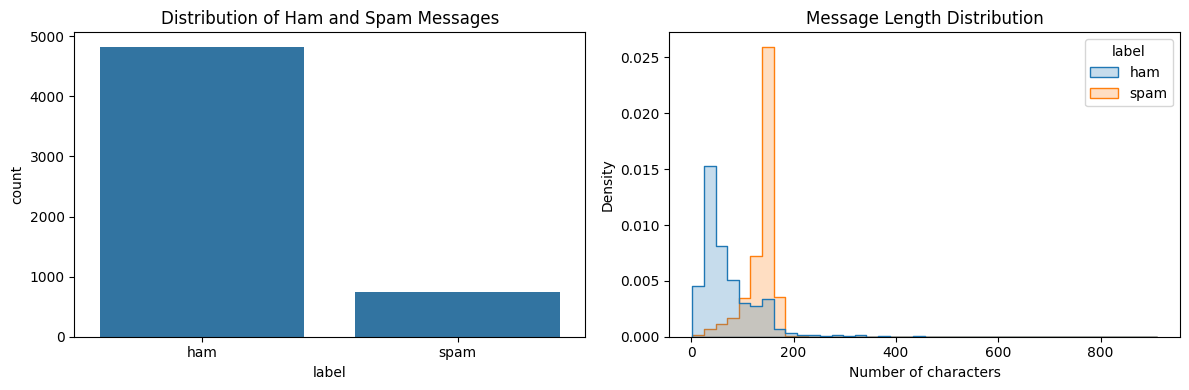

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="label", ax=axes[0])
axes[0].set_title("Distribution of Ham and Spam Messages")

sns.histplot(
    data=df, x="message_length", hue="label",
    bins=40, element="step", stat="density",
    common_norm=False, ax=axes[1]
)
axes[1].set_title("Message Length Distribution")
axes[1].set_xlabel("Number of characters")

plt.tight_layout()
plt.show()

**Interpretation:** Determine whether the classes are imbalanced and whether spam messages differ in length from legitimate messages. Do not assume that a longer message is necessarily spam

# 3. Prepare the Data


## a. Data Cleaning


In [18]:
df = df.dropna(subset=["label", "message"]).copy()

df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

df = df[
    df["label"].isin(["ham", "spam"]) &
    df["message"].ne("")
].copy()

# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Encode ham = 0 and spam = 1
df["target"] = df["label"].map({"ham": 0, "spam": 1})

print(df["target"].value_counts())

target
0    4516
1     653
Name: count, dtype: int64


For this baseline project, retain the original message wording and punctuation. Aggressive cleaning can remove useful spam signals, such as URLs, currency symbols, and repeated punctuation.

## b. Feature Selection

**Bag of Words**

Represents a message by word counts.

+ Example: “win win prize”
  * win = 2, prize = 1

**TF-IDF**

Weights terms based on their frequency in a message and rarity across the corpus.

Common terms tend to receive less weight than more distinctive terms.

## c. Data Transforms

# 4 Evaluate Algorithms

## a. Set aside validation dataset

We need to know whether or not the model that we created is any good. Later, we will use statistical methods to estimate the accuracy of the models that we create on unseen data. We also want a more concrete estimate of the accuracy of the best model on unseen data by evaluating it on actual unseen data. That is, we are going to hold back some data that the algorithms will not get to see and we will use this data to get a second and independent idea of how accurate the best model might actually be. We will split the loaded dataset into two, 80%
of which we will use to train our models and 20% that we will hold back as a validation dataset.

In [19]:
X = df["message"]
y = df["target"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

Training rows: 4135
Validation rows: 1034


You now have training data in the X train and Y train for preparing models and a
X validation and Y validation sets that we can use later.

## b. Establish a baseline

A simple baseline predicts the most frequent class every time. This helps determine whether a model is genuinely learning to identify spam rather than benefiting from class imbalance.

In [20]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train.to_frame(), y_train)

baseline_pred = baseline.predict(X_val.to_frame())

print("Baseline accuracy:",
      accuracy_score(y_val, baseline_pred))
print("Baseline spam F1:",
      f1_score(y_val, baseline_pred, pos_label=1))

Baseline accuracy: 0.8733075435203095
Baseline spam F1: 0.0


This baseline is for reference. The following comparisons use text features extracted within each pipeline.

## c. Spot-check

In [21]:
models = {
    "Linear SVM": LinearSVC(random_state=42),
    "RBF SVM": SVC(kernel="rbf"),
    "Multinomial NB": MultinomialNB(),
    "Bernoulli NB": BernoulliNB(),
    "Perceptron": Perceptron(random_state=42),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    )
}

vectorizers = {
    "BoW": CountVectorizer(
        stop_words=None,
        max_features=20000
    ),
    "TF-IDF": TfidfVectorizer(
        stop_words=None,
        max_features=20000,
        sublinear_tf=True
    )
}

## d. Compare algorithms

Use stratified five-fold cross-validation on the training data. This preserves the approximate ham/spam proportions in each fold.

In [22]:
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

results = []

for vector_name, vectorizer in vectorizers.items():
    for model_name, model in models.items():

        pipe = Pipeline([
            ("vectorizer", vectorizer),
            ("classifier", model)
        ])

        scores = cross_validate(
            pipe,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )

        results.append({
            "Features": vector_name,
            "Algorithm": model_name,
            "Accuracy mean": scores["test_accuracy"].mean(),
            "Precision mean": scores["test_precision"].mean(),
            "Recall mean": scores["test_recall"].mean(),
            "F1 mean": scores["test_f1"].mean(),
            "F1 std": scores["test_f1"].std()
        })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "F1 mean", ascending=False
    ).round(4)
)

,Features,Algorithm,Accuracy mean,Precision mean,Recall mean,F1 mean,F1 std
2,BoW,Multinomial NB,0.9840,0.9694,0.9023,0.9344,0.0105
6,TF-IDF,Linear SVM,0.9836,0.9813,0.8870,0.9317,0.0060
0,BoW,Linear SVM,0.9807,0.9766,0.8678,0.9187,0.0193
10,TF-IDF,Perceptron,0.9778,0.9222,0.9023,0.9115,0.0187
5,BoW,Logistic Regression,0.9785,0.9701,0.8562,0.9091,0.0158
7,TF-IDF,RBF SVM,0.9780,0.9933,0.8314,0.9050,0.0115
1,BoW,RBF SVM,0.9775,0.9931,0.8275,0.9024,0.0222
4,BoW,Perceptron,0.9739,0.9004,0.8946,0.8968,0.0227
3,BoW,Bernoulli NB,0.9703,0.9977,0.7662,0.8660,0.0261
9,TF-IDF,Bernoulli NB,0.9703,0.9977,0.7662,0.8660,0.0261


### Visualize the comparison

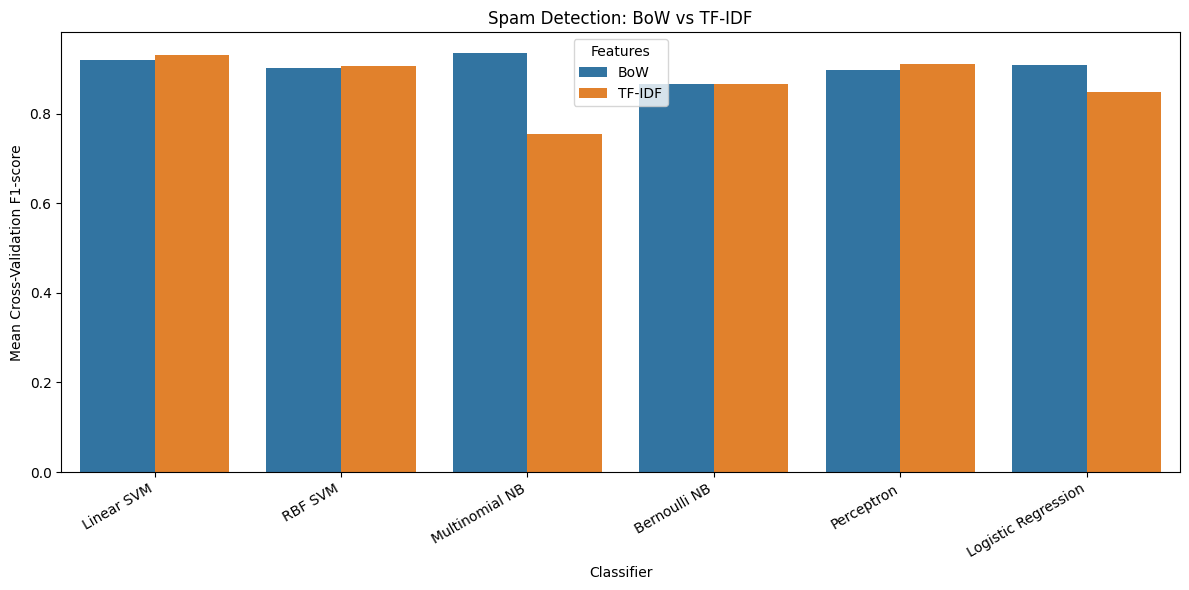

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="F1 mean",
    hue="Features"
)

plt.title("Spam Detection: BoW vs TF-IDF")
plt.ylabel("Mean Cross-Validation F1-score")
plt.xlabel("Classifier")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

How to interpret the results: Compare the F1-score for the spam class, precision, recall, and the variability across folds. For spam detection, high recall means catching more spam, while high precision means fewer legitimate messages are incorrectly flagged as spam.

# 5 Make Predictions

## a. Feature Scaling and transformations

For text classification, `BoW and TF-IDF` are the primary feature transformations. Unlike many numerical datasets, standardizing every sparse text feature with StandardScaler is usually unnecessary and can be inefficient. TF-IDF already applies term-frequency weighting and, by default, L2 normalization

## b. Fine-tune

The following example tunes a linear SVM using TF-IDF. It selects the best settings through cross-validation on the training data only.

In [25]:
svm_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=20000)),
    ("classifier", LinearSVC(random_state=42))
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "classifier__C": [0.1, 1, 10]
}

grid = GridSearchCV(
    svm_pipe,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation F1:", round(grid.best_score_, 4))

Best parameters: {'classifier__C': 1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
Best cross-validation F1: 0.9421


You can use a similar grid for Logistic Regression or Multinomial Naive Bayes. Select the final algorithm based on the evaluation objective, not accuracy alone

### c. Ensemble methods

A voting ensemble can combine different classifiers. This example uses TF-IDF features shared by Linear SVM, Logistic Regression, and Multinomial Naive Bayes

In [26]:
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)

ensemble = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=2000, random_state=42)),
        ("nb", MultinomialNB()),
        ("perceptron", Perceptron(random_state=42))
    ],
    voting="hard"
)

ensemble.fit(X_train_tfidf, y_train)

VotingClassifier(estimators=[('lr',
                              LogisticRegression(max_iter=2000,
                                                 random_state=42)),
                             ('nb', MultinomialNB()),
                             ('perceptron', Perceptron(random_state=42))])

Compare this ensemble with individual models using cross-validation before deciding whether it is worthwhile. Do not use validation results to choose the ensemble configuration

## Tune and compare

In [27]:
ensemble_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2)
    )),
    ("classifier", VotingClassifier(
        estimators=[
            ("lr", LogisticRegression(
                max_iter=2000, random_state=42
            )),
            ("nb", MultinomialNB()),
            ("perceptron", Perceptron(random_state=42))
        ],
        voting="hard"
    ))
])

for name, estimator in [
    ("Tuned Linear SVM", grid.best_estimator_),
    ("Voting Ensemble", ensemble_pipe)
]:
    scores = cross_validate(
        estimator, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1
    )
    print(
        name,
        "| Mean F1:", round(scores["test_f1"].mean(), 4),
        "| Mean precision:", round(scores["test_precision"].mean(), 4),
        "| Mean recall:", round(scores["test_recall"].mean(), 4)
    )

Tuned Linear SVM | Mean F1: 0.9421 | Mean precision: 0.9834 | Mean recall: 0.9042
Voting Ensemble | Mean F1: 0.8499 | Mean precision: 0.9976 | Mean recall: 0.7414


## 6. Finalize the Model

Use the tuned SVM as the example final candidate. The validation data is used for evaluation only at this stage.

Validation Accuracy: 0.9797

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       903
        Spam       0.96      0.88      0.92       131

    accuracy                           0.98      1034
   macro avg       0.97      0.94      0.95      1034
weighted avg       0.98      0.98      0.98      1034



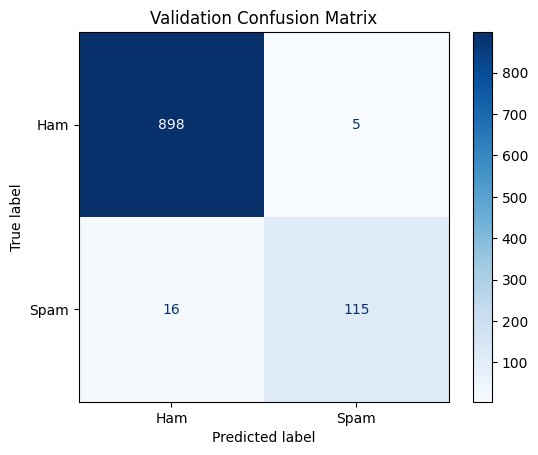

In [28]:
final_model = grid.best_estimator_

y_val_pred = final_model.predict(X_val)

print("Validation Accuracy:",
      round(accuracy_score(y_val, y_val_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    labels=[0, 1],
    display_labels=["Ham", "Spam"],
    cmap="Blues"
)

plt.title("Validation Confusion Matrix")
plt.show()

Pay particular attention to Spam recall and Spam precision. A false positive is a legitimate message classified as spam; a false negative is a spam message classified as legitimate.

The spam detection model achieved a validation accuracy of 97.97%, which indicates strong overall classification performance. However, the model is better at identifying legitimate messages (Ham) than detecting spam messages (Spam).

1True negatives: 8981

+ The model correctly identified 898 legitimate messages as Ham.

`False positives: 5`

+ Five legitimate messages were incorrectly classified as Spam.

`False negatives: 16`

+ Sixteen spam messages were incorrectly classified as Ham and could reach the user's inbox.

`True positives: 115`

+ The model correctly detected 115 spam messages.

The model performs well overall, but it misses approximately 12.21% of actual spam messages. Its spam precision is higher than its recall, meaning that when it flags a message as spam, it is usually correct, but it still fails to detect some spam.

**Interpretation**: Although your model has 97.97% overall accuracy, it still misses 16 spam messages in this validation set. This illustrates why accuracy alone is not enough to evaluate a spam detection model.

# 6. Final Deployment

In [29]:
deployment_model = grid.best_estimator_

deployment_model.fit(X, y)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=20000, min_df=2,
                                 ngram_range=(1, 2))),
                ('classifier', LinearSVC(C=1, random_state=42))])

If you need to preserve the exact model that was evaluated on the held-back set, save final_model instead of refitting it on all the data

In [30]:
os.makedirs("Models", exist_ok=True)

model_path = "Models/sms_spam_detector.joblib"

joblib.dump(deployment_model, model_path)

print("Model saved to:", model_path)

Model saved to: Models/sms_spam_detector.joblib


The saved pipeline includes the TF-IDF vectorizer and classifier, so new messages are transformed consistently before prediction.

In [42]:
# Get a message from the client
new_messages = input("Enter a message to check: ")

# Predict using the trained model
prediction = deployment_model.predict([message])[0]

# Display the result
if prediction == 1:
    print("Result: SPAM")
else:
    print("Result: HAM (Legitimate Message)")

Enter a message to check: Send a cash now
Result: SPAM
